<a href="https://colab.research.google.com/github/TZBDragon/LinAlg344TZB/blob/main/notebooks/03_measuring_compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
import os
import subprocess
import sys
USER = 'tzbdragon'
REPO = 'LinAlg344TZB'
if os.path.exists(REPO):
  subprocess.run(['git', '-C', REPO, 'pull'], check=True)
else:
  subprocess.run(
  ['git', 'clone', f'https://github.com/{USER}/{REPO}.git', REPO],
  check=True)
sys.path.insert(0, f'{REPO}/src')
from compress import rank_k_approx

Imports a rank_k_approx from a github repo and user as provided

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
A = data.camera().astype(float)
m, n = A.shape
T = data.text().astype(float)
print('Camera:', A.shape, 'Text:', T.shape)

Camera: (512, 512) Text: (172, 448)


imports data package and loads the picture we always use

In [24]:
def storage(m, n, k):
#Number of values needed to store a rank-k approximation.
  return k * (m + n + 1)
def compression_ratio(m, n, k):
#Original number of values divided by compressed number of values.
  return (m * n) / storage(m, n, k)
print('Original camera values:', m * n)
for k in [1, 10, 50, 100, 255, 256]:
  print(f'k={k:3d} stored={storage(m, n, k):6d}'
  f'ratio={compression_ratio(m, n, k):.2f}')

Original camera values: 262144
k=  1 stored=  1025ratio=255.75
k= 10 stored= 10250ratio=25.58
k= 50 stored= 51250ratio=5.12
k=100 stored=102500ratio=2.56
k=255 stored=261375ratio=1.00
k=256 stored=262400ratio=1.00


Calculates the compression ration with the number of values requires to store the image

In [25]:
def rel_error(A, B):
#Relative Frobenius error when B approximates A.
  return np.linalg.norm(A - B) / np.linalg.norm(A)
  for k in [1, 5, 20, 50, 100]:
    Ak = rank_k_approx(A, k)
    print(f'k={k:3d} relative error={rel_error(A, Ak):.4f}')

In [26]:
U, s, Vt = np.linalg.svd(A, full_matrices=False)
def predicted_error(s, k):
#Relative rank-k error computed from the singular values.
  return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))
  for k in [1, 5, 20, 50, 100]:
    actual = rel_error(A, rank_k_approx(A, k))
    predicted = predicted_error(s, k)
    print(f'k={k:3d} actual={actual:.6f} predicted={predicted:.6f}')

In [27]:
ks = np.arange(1, len(s) + 1)
errors = np.array([predicted_error(s, k) for k in ks])
for target in [0.10, 0.05, 0.02, 0.01]:
  k = ks[errors <= target][0]
  ratio = compression_ratio(m, n, k)
  print(f'k={k}, ratio={ratio:.2f}')

k=21, ratio=12.18
k=73, ratio=3.50
k=186, ratio=1.38
k=263, ratio=0.97


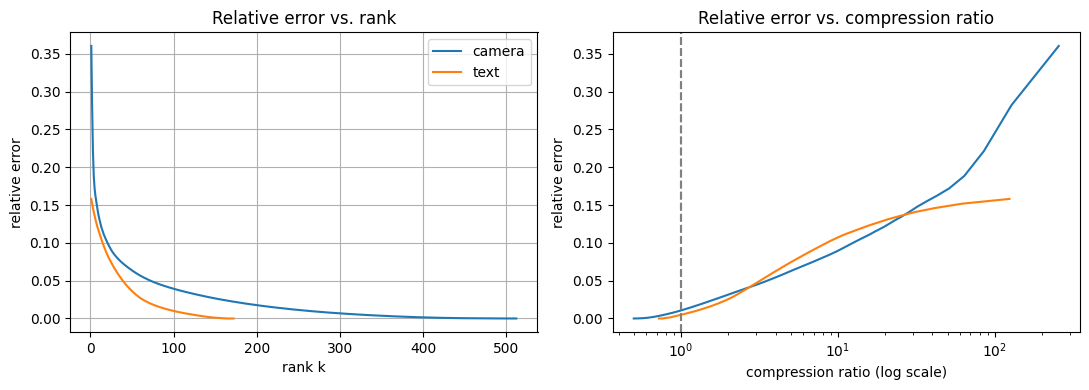

<Figure size 640x480 with 0 Axes>

In [30]:
images = {'camera': A, 'text': T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for name, M in images.items():
  m_img, n_img = M.shape
  s_img = np.linalg.svd(M, compute_uv=False)
  ranks = np.arange(1, len(s_img) + 1)
  errs = [predicted_error(s_img, k) for k in ranks]
  ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
  ax1.plot(ranks, errs, label=name)
  ax2.semilogx(ratios, errs, label=name)
  ax1.set_title('Relative error vs. rank')
  ax1.set_xlabel('rank k')
  ax1.set_ylabel('relative error')
  ax2.axvline(1, color='gray', linestyle='--', label='ratio = 1')
  ax2.set_title('Relative error vs. compression ratio')
  ax2.set_xlabel('compression ratio (log scale)')
  ax2.set_ylabel('relative error')
for ax in (ax1, ax2):
  ax.grid()
  ax.legend()
  plt.tight_layout()
  plt.savefig('error_vs_ratio.png', dpi=150)
  plt.show()

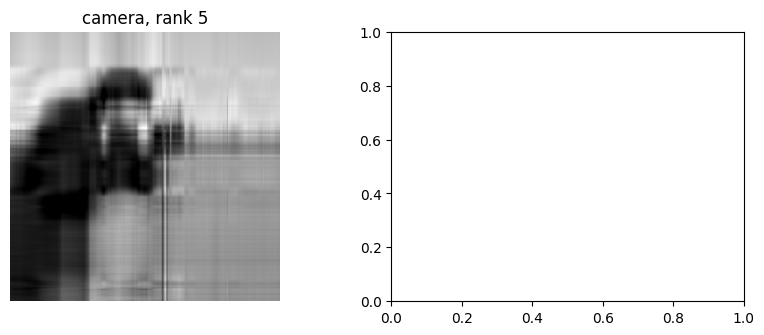

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
  Mk = np.clip(rank_k_approx(M, 5), 0, 255)
  ax.imshow(Mk, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'{name}, rank 5')
  ax.axis('off')
  plt.show()

In [35]:
A20 = rank_k_approx(A, 20)
outside = (A20 < 0) | (A20 > 255)
print('Out-of-range pixels:', outside.sum())
print('Fraction:', f'{outside.mean():.1%}')
print('Error before clipping:', round(rel_error(A, A20), 4))
print('Error after clipping:',
round(rel_error(A, np.clip(A20, 0, 255)), 4))

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


Saving TZB_9836.JPG to TZB_9836.JPG
Shape: (534, 800)
Data type: uint8


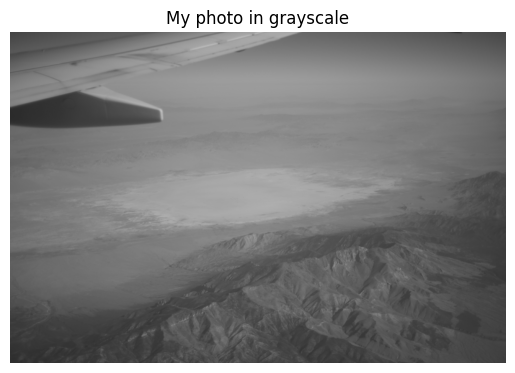

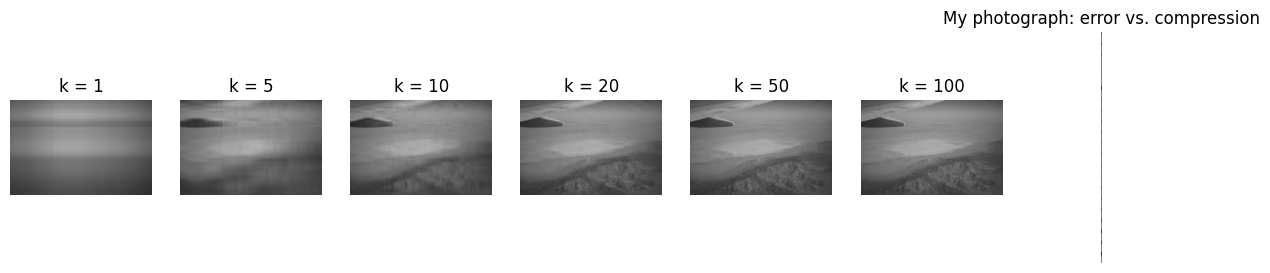

In [38]:
from google.colab import files
from PIL import Image
uploaded = files.upload()
name = list(uploaded)[0]
img = Image.open(name).convert("L")
img.thumbnail((800, 800))
P = np.array(img)
print("Shape:", P.shape)
print("Data type:", P.dtype)
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

ks = [1, 5, 10, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))
for ax, k in zip(axes, ks):
  Pk = np.clip(rank_k_approx(P, k), 0, 255)
  ax.imshow(Pk, cmap='gray', vmin=0, vmax=255)
  ax.set_title(f'k = {k}')
  ax.axis('off')

axes[-1].imshow(P, cmap='gray', vmin=0, vmax=255)
axes[-1].set_title('original')
axes[-1].axis('off')

P_float = P.astype(float)
sp = np.linalg.svd(P_float, compute_uv=False)
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]
plt.semilogx(rp, ep)
plt.axvline(1, color='gray', linestyle='--')
plt.xlabel('compression ratio (log scale)')
plt.ylabel('relative error')
plt.title('My photograph: error vs. compression')
plt.grid()
plt.show()

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# -----------------------------------------------------
# 1. When does compression stop saving values?
# -----------------------------------------------------
# Inequality: k(m + n + 1) < mn  =>  k < (mn) / (m + n + 1)
# Largest integer k is floor( (mn - 1) / (m + n + 1) )

def max_k_values(m, n):
    return (m * n - 1) // (m + n + 1)

# Camera image (512, 512)
m_cam, n_cam = 512, 512
k_cam_vals = max_k_values(m_cam, n_cam)

# Text image (172, 448)
m_txt, n_txt = 172, 448
k_txt_vals = max_k_values(m_txt, n_txt)

print("--- Part 1: Value vs Byte Thresholds ---")
print(f"Largest k saving values (Camera): {k_cam_vals} (Storage for k={k_cam_vals} is {k_cam_vals*(m_cam+n_cam+1)}, original={m_cam*n_cam})")
print(f"Largest k saving values (Text): {k_txt_vals} (Storage for k={k_txt_vals} is {k_txt_vals*(m_txt+n_txt+1)}, original={m_txt*n_txt})")

# Checking dtype and itemsize
print(f"U.dtype: {U.dtype}, U.itemsize: {U.itemsize} bytes (float64)")
# Original pixels: uint8 (1 byte per pixel)
# SVD representation: k * (m + n + 1) float64 values (8 bytes per value)
# Saving bytes condition: 8 * k * (m + n + 1) < 1 * m * n  =>  k < (m * n) / (8 * (m + n + 1))
def max_k_bytes(m, n):
    return (m * n - 1) // (8 * (m + n + 1))

k_cam_bytes = max_k_bytes(m_cam, n_cam)
k_txt_bytes = max_k_bytes(m_txt, n_txt)
print(f"Largest k saving bytes (Camera): {k_cam_bytes}")
print(f"Largest k saving bytes (Text): {k_txt_bytes}\n")


--- Part 1: Value vs Byte Thresholds ---
Largest k saving values (Camera): 255 (Storage for k=255 is 261375, original=262144)
Largest k saving values (Text): 124 (Storage for k=124 is 77004, original=77056)
U.dtype: float64, U.itemsize: 8 bytes (float64)
Largest k saving bytes (Camera): 31
Largest k saving bytes (Text): 15



In [40]:

# -----------------------------------------------------
# 2. Why does predicted error work?
# -----------------------------------------------------
print("--- Part 2: Frobenius Norm and Eckart-Young ---")
norm_A_sq = np.linalg.norm(A)**2
sum_s_sq = np.sum(s**2)
print(f"||A||^2 = {norm_A_sq:.6f}")
print(f"sum(s^2) = {sum_s_sq:.6f}")
print(f"Difference: {abs(norm_A_sq - sum_s_sq):.6e}\n")


--- Part 2: Frobenius Norm and Eckart-Young ---
||A||^2 = 5788200983.000001
sum(s^2) = 5788200983.000000
Difference: 9.536743e-07



--- Part 3: Text Image Histogram and Readability ---


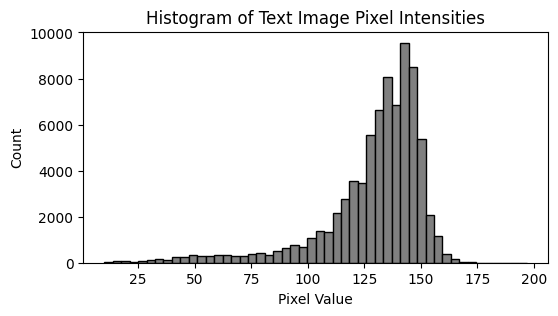

In [41]:

# -----------------------------------------------------
# 3. Numbers versus readability
# -----------------------------------------------------
print("--- Part 3: Text Image Histogram and Readability ---")
plt.figure(figsize=(6, 3))
plt.hist(T.ravel(), bins=50, color='gray', edgecolor='black')
plt.title("Histogram of Text Image Pixel Intensities")
plt.xlabel("Pixel Value")
plt.ylabel("Count")
plt.show()


In [42]:

# -----------------------------------------------------
# 4. Compare your own image
# -----------------------------------------------------
print("--- Part 4: Milestone Comparison at 10% Relative Error ---")
# Let's find compression ratios for Camera, Text, and Personal photo P at 10% error.
for name_img, (M_img, s_arr) in {
    'Camera': (A, np.linalg.svd(A, compute_uv=False)),
    'Text': (T, np.linalg.svd(T, compute_uv=False)),
    'My Photograph': (P_float, np.linalg.svd(P_float, compute_uv=False))
}.items():
    h, w = M_img.shape
    # predicted errors
    ranks_arr = np.arange(1, len(s_arr) + 1)
    errs_arr = np.array([predicted_error(s_arr, rank_k) for rank_k in ranks_arr])
    # rank at 10%
    k_10 = ranks_arr[errs_arr <= 0.10][0]
    ratio_10 = compression_ratio(h, w, k_10)
    print(f"{name_img:15s} size: {h}x{w:3d} | rank at 10% error: {k_10:3d} | ratio: {ratio_10:.2f}")
print()


--- Part 4: Milestone Comparison at 10% Relative Error ---
Camera          size: 512x512 | rank at 10% error:  21 | ratio: 12.18
Text            size: 172x448 | rank at 10% error:  15 | ratio: 8.27
My Photograph   size: 534x800 | rank at 10% error:   2 | ratio: 160.00



In [43]:

# -----------------------------------------------------
# 5. Prove clipping cannot increase error
# -----------------------------------------------------
# Mathematical verification / demonstration of clipping on out-of-range elements:
print("--- Part 5: Clipping Demonstration ---")
# Example values
a = 150
x_vals = [-50.0, 150.0, 300.0]
for x in x_vals:
    x_clipped = np.clip(x, 0, 255)
    print(f"a={a}, x={x:6.1f} => |x-a|={abs(x-a):5.1f} | x_clipped={x_clipped:5.1f} => |x_clipped-a|={abs(x_clipped-a):5.1f}")
print()


--- Part 5: Clipping Demonstration ---
a=150, x= -50.0 => |x-a|=200.0 | x_clipped=  0.0 => |x_clipped-a|=150.0
a=150, x= 150.0 => |x-a|=  0.0 | x_clipped=150.0 => |x_clipped-a|=  0.0
a=150, x= 300.0 => |x-a|=150.0 | x_clipped=255.0 => |x_clipped-a|=105.0



--- Part 6: Visual Comparison for My Photo ---


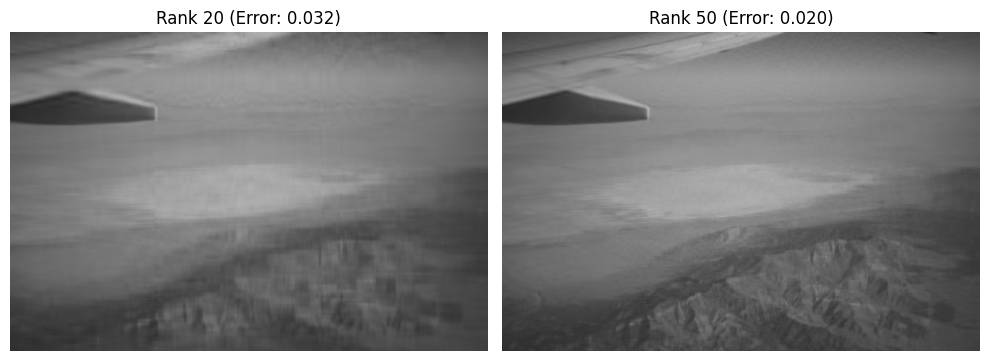

In [44]:

# -----------------------------------------------------
# 6. Choose a rank
# -----------------------------------------------------
print("--- Part 6: Visual Comparison for My Photo ---")
# Visual check of Rank 20 and Rank 50 for sharing
fig, axes_p = plt.subplots(1, 2, figsize=(10, 4))
for ax, k_choice in zip(axes_p, [20, 50]):
    Pk_choice = np.clip(rank_k_approx(P, k_choice), 0, 255)
    ax.imshow(Pk_choice, cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"Rank {k_choice} (Error: {predicted_error(sp, k_choice):.3f})")
    ax.axis('off')
plt.tight_layout()
plt.show()